# Unified Brain MRI End-to-End Pipeline — BraTS + RHUH

This Colab notebook combines single-case BraTS inference and RHUH longitudinal analysis: segmentation masks, tumor volumes, longitudinal changes, radiomics, reference-mask metrics when valid, QC figures, uncertainty outputs, summary files, and a ZIP bundle.

**Important:** the Drive project root and the RHUH processed-data root are discovered independently because shared-folder shortcuts can expose them at different paths. `BRATS_SINGLE` is the default, matching the previously working configuration. Change only `TASK_MODE` to `RHUH_LONGITUDINAL` to run the RHUH workflow.

The notebook checks required files before inference. It cannot guarantee zero runtime errors without running against the live Colab runtime and the exact Drive data. RHUH tumor label semantics and spatial registration must be validated before interpreting longitudinal changes.

## 1. Configuration — edit this cell only

Choose `BRATS_SINGLE` or `RHUH_LONGITUDINAL`. RHUH cleaned scans must follow the team notebook's layout:
`<BASE>/processed/rhuh/<subject>/<timepoint>/{t1,t1ce,t2,flair,seg}.nii.gz`
with timepoint folder names typically `0.0`, `1.0`, `2.0`.

For longitudinal changes, use at least two timepoints belonging to the same patient. Ensure that the scans are appropriately registered/aligned before interpreting changes. Leave the registered model and checkpoint settings unchanged.


In [2]:
from pathlib import Path
import os

# Mount Drive if needed.
from google.colab import drive
drive.mount("/content/drive", force_remount=False)

DRIVE = Path("/content/drive")
if not (DRIVE / "MyDrive").is_dir():
    raise RuntimeError("Google Drive is not mounted. Run drive.mount('/content/drive') and authorize access.")

# Keep the user's established project root. If a different root is needed, set this override.
BASE_OVERRIDE = None
DEFAULT_BASE = DRIVE / "MyDrive" / "BrainMRI_Data"

def _is_project_root(p: Path) -> bool:
    return p.is_dir() and (
        (p / "raw").is_dir() or
        (p / "runs" / "M2-T04_nnunet").is_dir() or
        (p / "pipeline").is_dir()
    )

def _unique_paths(paths):
    out, seen = [], set()
    for p in paths:
        try:
            q = p.resolve()
        except Exception:
            q = p
        key = str(q)
        if key not in seen:
            seen.add(key)
            out.append(p)
    return out

if BASE_OVERRIDE is not None:
    BASE = Path(BASE_OVERRIDE)
    if not _is_project_root(BASE):
        raise FileNotFoundError(f"BASE_OVERRIDE is not a recognizable BrainMRI_Data project root: {BASE}")
else:
    base_candidates = [DEFAULT_BASE, DRIVE / "My Drive" / "BrainMRI_Data"]
    for pattern in (
        ".shortcut-targets-by-id/*/BrainMRI_Data",
        "MyDrive/**/BrainMRI_Data",
        "Shareddrives/**/BrainMRI_Data",
        "Shared drives/**/BrainMRI_Data",
    ):
        try:
            base_candidates.extend(DRIVE.glob(pattern))
        except (OSError, PermissionError):
            pass
    base_candidates = _unique_paths([p for p in base_candidates if p.is_dir()])
    valid_bases = [p for p in base_candidates if _is_project_root(p)]
    if not valid_bases:
        raise FileNotFoundError(
            "Could not locate BrainMRI_Data. Ensure the shared folder is added as a shortcut to My Drive, "
            "or set BASE_OVERRIDE to the exact BrainMRI_Data path."
        )
    # Prefer the expected MyDrive root when it contains the project folders.
    BASE = DEFAULT_BASE if _is_project_root(DEFAULT_BASE) else sorted(valid_bases, key=lambda p: len(str(p)))[0]

REPO_URL = "https://github.com/nhahub/NHA-5-187.git"
BRANCH = "main"

# Select task mode. These defaults match the previously working BRATS_SINGLE configuration.
TASK_MODE = "BRATS_SINGLE"  # "BRATS_SINGLE" or "RHUH_LONGITUDINAL"

BRATS_CASE_ID = "BraTS2021_00000"
BRATS_CASE_DIR = BASE / "processed" / "brats2021" / BRATS_CASE_ID / "0"

RHUH_SUBJECT = "RHUH-0030"
RHUH_TIMEPOINTS = ("0.0", "1.0", "2.0")
RHUH_PAIRS = ((0, 1), (1, 2), (0, 2))
MIN_VOL_CM3_FOR_PERCENT_CHANGE = 0.1

# Output and uncertainty settings, matching the user's configuration.
OUT = BASE / "runs" / "Unified_End_to_End"
SAVE_RAD_FEATURES = True
RUN_OFFICIAL_UNCERTAINTY = True
UNCERTAINTY_CASES = 3
UNCERTAINTY_SAVE_MAPS = 1
MAX_HOURS_UNCERTAINTY = 2.0

# RHUH uncertainty is perturbation-stability analysis, not calibrated probability uncertainty.
RHUH_UNCERTAINTY_RUNS = 4
RHUH_UNCERTAINTY_SIGMA = 0.03

# RHUH may be in a different shared-folder shortcut from the MyDrive project root.
# Discover it independently instead of assuming BASE/processed/rhuh exists.
RHUH_ROOT_OVERRIDE = None
def _has_rhuh_cases(p: Path) -> bool:
    return p.is_dir() and any(x.is_dir() for x in p.iterdir())

if RHUH_ROOT_OVERRIDE is not None:
    RHUH_ROOT = Path(RHUH_ROOT_OVERRIDE)
else:
    rhuh_candidates = [
        BASE / "processed" / "rhuh",
        DRIVE / "MyDrive" / "BrainMRI_Data" / "processed" / "rhuh",
    ]
    for pattern in (
        ".shortcut-targets-by-id/*/BrainMRI_Data/processed/rhuh",
        ".shortcut-targets-by-id/*/processed/rhuh",
        "MyDrive/**/processed/rhuh",
        "Shareddrives/**/processed/rhuh",
        "Shared drives/**/processed/rhuh",
    ):
        try:
            rhuh_candidates.extend(DRIVE.glob(pattern))
        except (OSError, PermissionError):
            pass
    rhuh_candidates = _unique_paths([p for p in rhuh_candidates if p.is_dir()])
    RHUH_ROOT = next((p for p in rhuh_candidates if _has_rhuh_cases(p)), None)

print("Project root:", BASE)
print("Task mode:", TASK_MODE)
print("BraTS case path:", BRATS_CASE_DIR, "| exists:", BRATS_CASE_DIR.is_dir())
print("RHUH root detected:", RHUH_ROOT)
print("Registered checkpoint expected under:", BASE / "runs" / "M2-T04_nnunet" / "nnUNet_results")

Mounted at /content/drive
Project root: /content/drive/MyDrive/BrainMRI_Data
Task mode: BRATS_SINGLE
BraTS case path: /content/drive/MyDrive/BrainMRI_Data/processed/brats2021/BraTS2021_00000/0 | exists: False
RHUH root detected: None
Registered checkpoint expected under: /content/drive/MyDrive/BrainMRI_Data/runs/M2-T04_nnunet/nnUNet_results


In [3]:
from pathlib import Path

if TASK_MODE == "RHUH_LONGITUDINAL":
    if RHUH_ROOT is None or not Path(RHUH_ROOT).is_dir():
        raise FileNotFoundError(
            "RHUH_LONGITUDINAL selected, but no processed/rhuh folder was found in the mounted Drive. "
            "Set RHUH_ROOT_OVERRIDE in the configuration cell to the exact folder containing patient folders. "
            "The original data may still be under raw/longitudinal_rhuh_gbm; this notebook will not silently "
            "treat raw scans as standardized inputs."
        )
    subject_dir = Path(RHUH_ROOT) / RHUH_SUBJECT
    if not subject_dir.is_dir():
        available = sorted(p.name for p in Path(RHUH_ROOT).iterdir() if p.is_dir())[:30]
        raise FileNotFoundError(
            f"RHUH subject folder not found: {subject_dir}. Available subject examples: {available}. "
            "Update RHUH_SUBJECT to an existing folder name."
        )
    required_files = ("t1.nii.gz", "t1ce.nii.gz", "t2.nii.gz", "flair.nii.gz", "seg.nii.gz")
    for tp in RHUH_TIMEPOINTS:
        folder = subject_dir / str(tp)
        if not folder.is_dir():
            available_tp = sorted(p.name for p in subject_dir.iterdir() if p.is_dir())
            raise FileNotFoundError(f"Missing RHUH timepoint directory: {folder}. Available: {available_tp}")
        missing = [name for name in required_files if not (folder / name).is_file()]
        if missing:
            raise FileNotFoundError(f"{RHUH_SUBJECT}/{tp}: missing required files: {missing}")
        print(f"Preflight OK: {RHUH_SUBJECT}/{tp}")
    print("RHUH preflight passed. Registration and label semantics must still be validated.")
else:
    if not BRATS_CASE_DIR.is_dir():
        print("Requested cleaned BraTS case is not at the default processed path.")
        print("The setup cell may prepare it from raw data if the project standardize.py supports this dataset.")
    else:
        print("BraTS case folder found:", BRATS_CASE_DIR)

Requested cleaned BraTS case is not at the default processed path.
The setup cell may prepare it from raw data if the project standardize.py supports this dataset.


## RHUH-specific validation notes

This configuration is set to `RHUH-0030` at timepoints `0.0`, `1.0`, and `2.0` using the verified shared-Drive shortcut path. The preflight below confirms file presence only. It does **not** prove that timepoints are registered to one another or that RHUH mask labels have the same meaning as BraTS labels. Review the dataset's label mapping before interpreting TC/WT/ET volumes or longitudinal changes. The official project uncertainty script is BraTS-cohort-only; this RHUH run will report uncertainty as unsupported/not run rather than fabricate an uncertainty map.

## 2. Mount Drive, install project-compatible packages, and fetch the team repository

In [4]:
from google.colab import drive
from pathlib import Path
import os, sys, json, hashlib, subprocess, shutil, glob, math, time

# Drive may already be mounted in Colab; this is normal and not an error.
drive.mount("/content/drive", force_remount=False)

OUT = BASE / "runs/Unified_End_to_End"
OUT.mkdir(parents=True, exist_ok=True)
REPO = Path("/content/repo")
if (REPO / ".git").exists():
    subprocess.run(["git", "-C", str(REPO), "fetch", "origin"], check=True)
    subprocess.run(["git", "-C", str(REPO), "checkout", BRANCH], check=True)
    subprocess.run(["git", "-C", str(REPO), "pull", "--ff-only", "origin", BRANCH], check=True)
else:
    subprocess.run(["git", "clone", "-b", BRANCH, REPO_URL, str(REPO)], check=True)

# Install the core dependencies separately. Keeping PyRadiomics separate avoids hiding
# a PyRadiomics build failure behind a generic CalledProcessError on newer Colab Python.
def pip_install(packages, extra_args=None):
    cmd = [sys.executable, "-m", "pip", "install", "--upgrade"]
    if extra_args:
        cmd.extend(extra_args)
    cmd.extend(packages)
    print("Installing:", " ".join(cmd))
    subprocess.run(cmd, check=True)

# Install the project dependencies without forcing an unnecessary full environment upgrade.
pip_install(["nnunetv2==2.8.1", "SimpleITK>=2.2.1", "pandas", "nibabel", "matplotlib", "tqdm"])
# Required by the repository uncertainty workflow (scripts/uncertainty.py imports monai.data).
pip_install(["monai", "bottleneck>=1.5.0"])
try:
    pip_install(["pyradiomics"])
except subprocess.CalledProcessError:
    # PyRadiomics 3.0.1 can fail to build on Python 3.12/3.13. Try the published
    # compatibility wheels referenced in the upstream Python-version issue.
    print("Standard PyRadiomics install failed; trying Python 3.12/3.13 compatibility wheels.")
    pip_install(["pyradiomics"], ["--find-links", "https://github.com/steubk/pyradiomics/releases/expanded_assets/prebuilt-fix-py312"])

import numpy as np
import pandas as pd
import nibabel as nib
import SimpleITK as sitk
from radiomics import featureextractor

sys.path.insert(0, str(REPO / "src"))
for key in ("nnUNet_raw", "nnUNet_preprocessed"):
    p = Path("/content/nnunet_work") / key
    p.mkdir(parents=True, exist_ok=True)
    os.environ[key] = str(p)
MODEL_RESULTS = BASE / "runs/M2-T04_nnunet/nnUNet_results"
MODEL_DIR = MODEL_RESULTS / "Dataset501_BraTS2021/nnUNetTrainer_50epochs__nnUNetPlans__3d_fullres"
os.environ["nnUNet_results"] = str(MODEL_RESULTS)
print("Python:", sys.version)
print("NumPy:", np.__version__, "Pandas:", pd.__version__)
print("Repo:", subprocess.check_output(["git", "-C", str(REPO), "rev-parse", "--short", "HEAD"], text=True).strip())
print("Drive base exists:", BASE.exists())
print("Model folder exists:", MODEL_DIR.exists())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Installing: /usr/bin/python3 -m pip install --upgrade nnunetv2==2.8.1 SimpleITK>=2.2.1 pandas nibabel matplotlib tqdm
Installing: /usr/bin/python3 -m pip install --upgrade monai bottleneck>=1.5.0
Installing: /usr/bin/python3 -m pip install --upgrade pyradiomics
Standard PyRadiomics install failed; trying Python 3.12/3.13 compatibility wheels.
Installing: /usr/bin/python3 -m pip install --upgrade --find-links https://github.com/steubk/pyradiomics/releases/expanded_assets/prebuilt-fix-py312 pyradiomics
Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
NumPy: 2.1.3 Pandas: 3.1.0
Repo: b34714b
Drive base exists: True
Model folder exists: True


## 2B. Drive/data preflight
This checks that the expected project root and registered checkpoint locations are present before model inference. If the shared folder was not added to My Drive, correct `BASE` in the configuration cell and rerun from the top.

In [5]:
from pathlib import Path
print('Project root:', BASE, '| exists:', BASE.is_dir())
print('Processed directory:', BASE / 'processed', '| exists:', (BASE / 'processed').is_dir())
print('Model results directory:', MODEL_RESULTS, '| exists:', MODEL_RESULTS.is_dir())
print('Registered checkpoint:', checkpoint if 'checkpoint' in globals() else MODEL_DIR / 'fold_0' / 'checkpoint_best.pth')
if not BASE.is_dir():
    raise FileNotFoundError(f'Project data root not found: {BASE}. Mount the shared Drive folder / add a shortcut to My Drive, or update BASE in the configuration cell.')
if not MODEL_DIR.is_dir():
    raise FileNotFoundError(f'Registered model folder not found: {MODEL_DIR}. Confirm that M2-T04 checkpoint files are in BrainMRI_Data/runs/M2-T04_nnunet/nnUNet_results/.')
print('Preflight passed: project root and model results folder are available.')


Project root: /content/drive/MyDrive/BrainMRI_Data | exists: True
Processed directory: /content/drive/MyDrive/BrainMRI_Data/processed | exists: True
Model results directory: /content/drive/MyDrive/BrainMRI_Data/runs/M2-T04_nnunet/nnUNet_results | exists: True
Registered checkpoint: /content/drive/MyDrive/BrainMRI_Data/runs/M2-T04_nnunet/nnUNet_results/Dataset501_BraTS2021/nnUNetTrainer_50epochs__nnUNetPlans__3d_fullres/fold_0/checkpoint_best.pth
Preflight passed: project root and model results folder are available.


## 3. Validate the registered model and cleaned scan files

In [6]:
manifest_path = REPO / "models/registry/seg-model/v1/manifest.json"
if not manifest_path.is_file():
    raise FileNotFoundError(f"Project model manifest missing: {manifest_path}. Check repository branch/access.")
manifest = json.loads(manifest_path.read_text())
checkpoint = MODEL_DIR / "fold_0" / manifest["nnunet"]["checkpoint"]
if not checkpoint.is_file():
    raise FileNotFoundError(f"Registered checkpoint missing: {checkpoint}. Complete M2-T04 model setup first.")
sha = hashlib.sha256()
with checkpoint.open("rb") as f:
    for block in iter(lambda: f.read(1 << 20), b""):
        sha.update(block)
if sha.hexdigest() != manifest["checkpoint_file"]["sha256"]:
    raise RuntimeError("Checkpoint SHA-256 does not match seg-model v1 manifest; refusing to run with an unverified model.")
print("Registered seg-model v1 checkpoint verified:", checkpoint.name)

MODS = ("t1", "t1ce", "t2", "flair")
# Canonical labels in the registered model: 1, 2, 3.
REGIONS = {"TC": (1, 3), "WT": (1, 2, 3), "ET": (3,)}

def validate_scan_folder(folder, require_seg=False):
    folder = Path(folder)
    if not folder.is_dir():
        raise FileNotFoundError(f"Scan folder not found: {folder}")
    paths = {m: folder / f"{m}.nii.gz" for m in MODS}
    if require_seg:
        paths["seg"] = folder / "seg.nii.gz"
    missing = [str(p) for p in paths.values() if not p.is_file()]
    if missing:
        raise FileNotFoundError("Required file(s) missing:\n" + "\n".join(missing))
    imgs = {k: nib.load(str(v)) for k, v in paths.items()}
    ref = imgs[MODS[0]]
    for name, img in imgs.items():
        if img.shape[:3] != ref.shape[:3] or not np.allclose(img.affine, ref.affine, atol=1e-4):
            raise ValueError(f"Geometry mismatch in {name}: shape/affine differs from t1 in {folder}")
    return paths

def _case_folder_candidates(case_id):
    return [
        BASE / "processed" / "brats2021" / case_id / "0",
        Path("/content/processed/brats2021") / case_id / "0",
        Path("/content/processed") / "brats2021" / case_id / "0",
        BASE / "processed" / case_id / "0",
    ]

def _is_valid_case_folder(folder):
    return folder.is_dir() and all((folder / f"{m}.nii.gz").is_file() for m in MODS)

def _find_cleaned_archive():
    expected = BASE / "processed" / "brats2021_trainval_v1.tar"
    if expected.is_file():
        return expected
    processed_root = BASE / "processed"
    if processed_root.is_dir():
        matches = list(processed_root.glob("**/brats2021_trainval_v1.tar"))
        if matches:
            print("Found cleaned archive at alternate location:", matches[0])
            return matches[0]
    return None

def _discover_existing_cases(case_id):
    candidates = []
    for candidate in _case_folder_candidates(case_id):
        if _is_valid_case_folder(candidate):
            candidates.append(candidate)
    for root in (BASE / "processed", Path("/content/processed")):
        if root.is_dir():
            for modality_path in root.glob("**/t1.nii.gz"):
                folder = modality_path.parent
                if folder.name == "0" and folder.parent.name == case_id and _is_valid_case_folder(folder):
                    candidates.append(folder)
    return list(dict.fromkeys(candidates))

def _prepare_brats_data(case_id):
    found = _discover_existing_cases(case_id)
    if found:
        return found[0]
    processed_root = Path("/content/processed/brats2021")
    archive = _find_cleaned_archive()
    if archive:
        print(f"Cleaned case not found; restoring the project's cleaned archive: {archive}")
        Path("/content/processed").mkdir(parents=True, exist_ok=True)
        subprocess.run(["tar", "-tf", str(archive)], check=True, stdout=subprocess.DEVNULL)
        subprocess.run(["tar", "-xf", str(archive), "-C", "/content/processed"], check=True)
        found = _discover_existing_cases(case_id)
        if found:
            return found[0]
        examples = [p.parent.name for p in processed_root.glob("*/0")][:10]
        raise FileNotFoundError(
            f"Archive extracted but case {case_id} was not found. Example cases: {examples}"
        )

    standardize_path = BASE / "pipeline" / "standardize.py"
    if standardize_path.is_file():
        print("No cleaned archive found. Preparing cleaned BraTS train/validation scans with standardize.py.")
        sys.path.insert(0, str(BASE / "pipeline"))
        import importlib
        if "standardize" in sys.modules:
            S = importlib.reload(sys.modules["standardize"])
        else:
            import standardize as S
        jobs = S.regenerate(splits=("train", "val"), datasets=("brats2021",))
        if hasattr(jobs, "status") and (jobs.status == "failed").any():
            raise RuntimeError("standardize.py reported failed jobs:\n" + jobs[jobs.status == "failed"].head(10).to_string(index=False))
        found = _discover_existing_cases(case_id)
        if found:
            try:
                archive_out = BASE / "processed" / "brats2021_trainval_v1.tar"
                archive_out.parent.mkdir(parents=True, exist_ok=True)
                if processed_root.is_dir():
                    print("Saving cleaned BraTS archive for future runs:", archive_out)
                    subprocess.run(["tar", "-cf", str(archive_out), "-C", "/content/processed", "brats2021"], check=True)
            except Exception as e:
                print("Warning: cleaned scans generated, but archive caching failed:", repr(e))
            return found[0]

    available = []
    for root in (BASE / "processed", Path("/content/processed")):
        if root.is_dir():
            for t1 in root.glob("**/t1.nii.gz"):
                folder = t1.parent
                if folder.name == "0" and _is_valid_case_folder(folder):
                    available.append(folder.parent.name)
    raise FileNotFoundError(
        "No usable cleaned BraTS scan was found and no usable cleaned archive was available.\n"
        f"Expected archive: {BASE / 'processed/brats2021_trainval_v1.tar'}\n"
        f"Project cleaner checked: {standardize_path}\n"
        f"Available case IDs: {sorted(set(available))[:20] or 'none'}"
    )

if TASK_MODE == "BRATS_SINGLE":
    BRATS_CASE_DIR = _prepare_brats_data(BRATS_CASE_ID)
    scan_specs = [(BRATS_CASE_ID, BRATS_CASE_DIR)]
elif TASK_MODE == "RHUH_LONGITUDINAL":
    if len(RHUH_TIMEPOINTS) < 2:
        raise ValueError("RHUH_LONGITUDINAL requires at least two timepoints.")
    if len(set(RHUH_TIMEPOINTS)) != len(RHUH_TIMEPOINTS):
        raise ValueError("RHUH_TIMEPOINTS contains duplicates; each timepoint must be unique.")
    rhuh_patient_dir = RHUH_ROOT / RHUH_SUBJECT
    if not rhuh_patient_dir.is_dir():
        discovered = sorted(p.name for p in RHUH_ROOT.iterdir() if p.is_dir()) if RHUH_ROOT.is_dir() else []
        raise FileNotFoundError(
            f"RHUH subject folder not found: {rhuh_patient_dir}\n"
            f"Available subject folders under {RHUH_ROOT}: {discovered[:30] or 'none'}"
        )
    available_tp = sorted(p.name for p in rhuh_patient_dir.iterdir() if p.is_dir())
    missing_tp = [tp for tp in RHUH_TIMEPOINTS if not (rhuh_patient_dir / tp).is_dir()]
    if missing_tp:
        raise FileNotFoundError(
            f"Requested RHUH timepoint folder(s) missing for {RHUH_SUBJECT}: {missing_tp}\n"
            f"Available timepoints: {available_tp}\n"
            "Edit RHUH_TIMEPOINTS in the configuration cell to match the actual folder names."
        )
    scan_specs = [(f"{RHUH_SUBJECT}_tp{tp}", rhuh_patient_dir / tp) for tp in RHUH_TIMEPOINTS]
else:
    raise ValueError("TASK_MODE must be BRATS_SINGLE or RHUH_LONGITUDINAL")

for case_id, folder in scan_specs:
    validate_scan_folder(folder, require_seg=(TASK_MODE == "RHUH_LONGITUDINAL"))
    print("Validated", case_id, "->", folder)
print(f"Preflight passed for {len(scan_specs)} scan(s) in mode {TASK_MODE}.")


Registered seg-model v1 checkpoint verified: checkpoint_best.pth
No cleaned archive found. Preparing cleaned BraTS train/validation scans with standardize.py.


brats2021:   0%|          | 0.00/13.4G [00:00<?, ?B/s]

  0%|          | 0/5315 [00:00<?, ?it/s]

status
done    5315
Saving cleaned BraTS archive for future runs: /content/drive/MyDrive/BrainMRI_Data/processed/brats2021_trainval_v1.tar
Validated BraTS2021_00000 -> /content/processed/brats2021/BraTS2021_00000/0
Preflight passed for 1 scan(s) in mode BRATS_SINGLE.


## 4. Run nnU-Net inference on the selected scan(s)

In [7]:
IN_DIR = OUT / "nnunet_input"
PRED_DIR = OUT / "predictions"
IN_DIR.mkdir(parents=True, exist_ok=True)
PRED_DIR.mkdir(parents=True, exist_ok=True)

# Fail early with a clear message if nnU-Net's executable or registered model is unavailable.
import shutil
nnunet_executable = shutil.which("nnUNetv2_predict")
if nnunet_executable is None:
    raise RuntimeError(
        "nnUNetv2_predict was not found in this runtime. Run the dependency/setup cell (cell 4) "
        "from the beginning, then retry."
    )
if not MODEL_DIR.is_dir():
    raise FileNotFoundError(f"Registered nnU-Net model directory is missing: {MODEL_DIR}")
if not (MODEL_DIR / "fold_0" / "checkpoint_best.pth").is_file():
    raise FileNotFoundError(
        f"Expected checkpoint is missing: {MODEL_DIR / 'fold_0' / 'checkpoint_best.pth'}"
    )

# Remove stale nnU-Net input files from an earlier run; only the current selected cases are sent.
for stale in IN_DIR.glob("*_????.nii.gz"):
    stale.unlink()
case_to_pred_name = {}
for case_id, folder in scan_specs:
    paths = validate_scan_folder(folder)
    for i, modality in enumerate(MODS):
        dst = IN_DIR / f"{case_id}_{i:04d}.nii.gz"
        shutil.copy2(paths[modality], dst)
    case_to_pred_name[case_id] = f"{case_id}.nii.gz"
    # Do not let an old prediction satisfy the output check after a failed inference.
    (PRED_DIR / f"{case_id}.nii.gz").unlink(missing_ok=True)

# Compatibility fix for CPU-only Colab runtimes with newer PyTorch.
# Some nnU-Net versions call Tensor.pin_memory() unconditionally. In a runtime
# without an available accelerator, that raises: "Cannot access accelerator device when none is available."
# Patch the installed nnU-Net iterator safely, without changing the trainer,
# dataset ID, checkpoint, or prediction settings.
import shlex
_predict_script = Path(nnunet_executable)
_shebang = _predict_script.read_text(errors="ignore").splitlines()[0]
if _shebang.startswith("#!"):
    _interpreter_parts = shlex.split(_shebang[2:].strip())
    if _interpreter_parts and Path(_interpreter_parts[0]).name == "env":
        _python_for_predict = shutil.which(_interpreter_parts[-1])
    else:
        _python_for_predict = _interpreter_parts[0] if _interpreter_parts else None
else:
    _python_for_predict = None
if not _python_for_predict:
    raise RuntimeError(f"Could not determine Python interpreter for {_predict_script}")
_probe = subprocess.run(
    [_python_for_predict, "-c", "import nnunetv2.inference.data_iterators as m; print(m.__file__)"],
    text=True, capture_output=True, check=False
)
if _probe.returncode != 0:
    raise RuntimeError(
        "Could not locate nnU-Net's data iterator using the predictor's Python interpreter. "
        f"Details: {_probe.stderr.strip()}"
    )
_iterator_file = Path(_probe.stdout.strip().splitlines()[-1])
_iterator_source = _iterator_file.read_text()
_pin_expression = "[i.pin_memory() for i in item.values() if isinstance(i, torch.Tensor)]"
_cpu_safe_expression = "([i.pin_memory() for i in item.values() if isinstance(i, torch.Tensor)] if torch.cuda.is_available() else [])"
if _pin_expression in _iterator_source:
    _iterator_file.write_text(_iterator_source.replace(_pin_expression, _cpu_safe_expression))
    print("Applied CPU-safe nnU-Net pin_memory compatibility patch:", _iterator_file)
elif _cpu_safe_expression in _iterator_source:
    print("CPU-safe nnU-Net pin_memory compatibility patch already present.")
else:
    raise RuntimeError(
        "The installed nnU-Net data iterator does not contain the expected pin_memory expression. "
        "No model/checkpoint settings were changed. Inspect this file before proceeding: "
        f"{_iterator_file}"
    )

# Explicitly choose an inference device. This prevents nnU-Net from selecting CUDA
# when PyTorch was installed without CUDA support (the error in the previous run).
import torch
_cuda_build_available = bool(getattr(torch, "version", None) and torch.version.cuda)
_cuda_runtime_available = bool(_cuda_build_available and torch.cuda.is_available())
if _cuda_runtime_available:
    _device_args = ["-device", "cuda"]
    print("Inference device: CUDA (PyTorch CUDA build and runtime are available).")
else:
    _device_args = ["-device", "cpu"]
    print(
        "Inference device: CPU. CUDA is unavailable to this PyTorch runtime; "
        "the trainer, dataset ID, and checkpoint remain unchanged. CPU inference may be slower."
    )

cmd = [
    nnunet_executable, "-i", str(IN_DIR), "-o", str(PRED_DIR),
    "-d", "501", "-c", "3d_fullres", "-f", "0",
    "-tr", "nnUNetTrainer_50epochs", "-chk", "checkpoint_best.pth",
    *_device_args,
]
print("Running:", " ".join(cmd))
print("nnUNet_results:", os.environ.get("nnUNet_results"))
print("nnUNet_raw:", os.environ.get("nnUNet_raw"))
print("nnUNet_preprocessed:", os.environ.get("nnUNet_preprocessed"))

# Capture and display the underlying error instead of only showing CalledProcessError.
result = subprocess.run(cmd, text=True, capture_output=True, check=False)
if result.stdout:
    print("\n===== nnU-Net STDOUT =====")
    print(result.stdout)
if result.stderr:
    print("\n===== nnU-Net STDERR =====")
    print(result.stderr)
if result.returncode != 0:
    raise RuntimeError(
        f"nnUNetv2_predict failed with exit code {result.returncode}. "
        "The detailed STDOUT/STDERR printed above identifies the underlying cause. "
        "Do not change the trainer, dataset ID, or checkpoint until that message is reviewed."
    )

for case_id, _ in scan_specs:
    pred = PRED_DIR / f"{case_id}.nii.gz"
    if not pred.is_file():
        raise FileNotFoundError(f"nnU-Net completed without expected prediction: {pred}")
    pred_img = nib.load(str(pred))
    labels_found = set(np.unique(np.asarray(pred_img.dataobj)).astype(int).tolist())
    if not labels_found.issubset({0, 1, 2, 3}):
        raise ValueError(
            f"Unexpected segmentation labels for {case_id}: {sorted(labels_found)}; "
            "expected canonical labels 0-3."
        )
print("Predictions ready:", len(scan_specs))


Applied CPU-safe nnU-Net pin_memory compatibility patch: /usr/local/lib/python3.13/dist-packages/nnunetv2/inference/data_iterators.py
Inference device: CUDA (PyTorch CUDA build and runtime are available).
Running: /usr/local/bin/nnUNetv2_predict -i /content/drive/MyDrive/BrainMRI_Data/runs/Unified_End_to_End/nnunet_input -o /content/drive/MyDrive/BrainMRI_Data/runs/Unified_End_to_End/predictions -d 501 -c 3d_fullres -f 0 -tr nnUNetTrainer_50epochs -chk checkpoint_best.pth -device cuda
nnUNet_results: /content/drive/MyDrive/BrainMRI_Data/runs/M2-T04_nnunet/nnUNet_results
nnUNet_raw: /content/nnunet_work/nnUNet_raw
nnUNet_preprocessed: /content/nnunet_work/nnUNet_preprocessed

===== nnU-Net STDOUT =====

#######################################################################
Please cite the following paper when using nnU-Net:
Isensee, F., Jaeger, P. F., Kohl, S. A., Petersen, J., & Maier-Hein, K. H. (2021). nnU-Net: a self-configuring method for deep learning-based biomedical image segme

## 5. Calculate TC / WT / ET volumes and longitudinal changes

In [8]:
def volume_from_mask(mask_path, case_id=None, source="prediction"):
    mask_path = Path(mask_path)
    img = nib.load(str(mask_path))
    seg = np.asarray(img.dataobj)
    zooms = img.header.get_zooms()[:3]
    units = img.header.get_xyzt_units()[0]
    voxel_mm3 = float(np.prod(zooms))
    if units in ("meter", "meters"):
        voxel_mm3 *= 1e9
    elif units in ("micron", "microns"):
        voxel_mm3 /= 1e9
    # This project's standardized NIfTI scans use millimetres; unknown units are
    # reported explicitly and interpreted as mm only for this project pipeline.
    row = {
        "case_id": case_id or mask_path.name.removesuffix(".nii.gz"),
        "source": source,
        "mask_path": str(mask_path),
        "voxel_units": units or "unknown_assumed_mm",
        "voxel_volume_mm3": voxel_mm3,
    }
    found_labels = set(np.unique(seg).astype(int).tolist())
    if not found_labels.issubset({0, 1, 2, 3}):
        raise ValueError(
            f"Unexpected labels in {mask_path}: {sorted(found_labels)}; "
            "expected standardized labels 0, 1, 2, 3."
        )
    for region, labels in REGIONS.items():
        row[f"{region}_cm3"] = float(np.isin(seg, labels).sum() * voxel_mm3 / 1000.0)
    if row["ET_cm3"] > row["TC_cm3"] + 1e-6 or row["TC_cm3"] > row["WT_cm3"] + 1e-6:
        raise ValueError(f"Region nesting failed for {mask_path}: expected ET <= TC <= WT.")
    return row

prediction_volume_rows = [
    volume_from_mask(PRED_DIR / f"{case_id}.nii.gz", case_id=case_id, source="prediction")
    for case_id, _ in scan_specs
]
all_volume_rows = list(prediction_volume_rows)

# For longitudinal RHUH scans, calculate volumes from expert reference masks as well,
# so the report contains a separate reference-vs-prediction comparison.
if TASK_MODE == "RHUH_LONGITUDINAL":
    expert_volume_rows = []
    for case_id, folder in scan_specs:
        expert_mask = Path(folder) / "seg.nii.gz"
        expert_volume_rows.append(
            volume_from_mask(expert_mask, case_id=case_id, source="expert")
        )
    all_volume_rows.extend(expert_volume_rows)

volumes_df = pd.DataFrame(all_volume_rows)
volumes_path = OUT / "tumor_volumes.csv"
volumes_df.to_csv(volumes_path, index=False)
print(volumes_df.to_string(index=False))

changes_path = None
if TASK_MODE == "RHUH_LONGITUDINAL":
    valid_pairs = [pair for pair in RHUH_PAIRS if len(pair) == 2 and 0 <= pair[0] < len(scan_specs) and 0 <= pair[1] < len(scan_specs) and pair[0] != pair[1]]
    if not valid_pairs:
        raise ValueError("No valid RHUH_PAIRS found. Use pairs of indices into RHUH_TIMEPOINTS, e.g. ((0, 1), (1, 2), (0, 2)).")
    changes = []
    for source in ("expert", "prediction"):
        source_rows = {row["case_id"]: row for row in all_volume_rows if row["source"] == source}
        for earlier_idx, later_idx in valid_pairs:
            earlier_id = scan_specs[earlier_idx][0]
            later_id = scan_specs[later_idx][0]
            earlier = source_rows[earlier_id]
            later = source_rows[later_id]
            for region in REGIONS:
                v0 = float(earlier[f"{region}_cm3"])
                v1 = float(later[f"{region}_cm3"])
                changes.append({
                    "subject": RHUH_SUBJECT,
                    "source": source,
                    "baseline_case": earlier_id,
                    "followup_case": later_id,
                    "region": region,
                    "baseline_cm3": v0,
                    "followup_cm3": v1,
                    "absolute_change_cm3": v1 - v0,
                    "change_percent": ((v1 - v0) / v0 * 100.0) if v0 >= MIN_VOL_CM3_FOR_PERCENT_CHANGE else np.nan,
                    "percent_change_status": "ok" if v0 >= MIN_VOL_CM3_FOR_PERCENT_CHANGE else f"baseline_below_{MIN_VOL_CM3_FOR_PERCENT_CHANGE}_cm3",
                })
    changes_df = pd.DataFrame(changes)
    changes_path = OUT / "longitudinal_changes.csv"
    changes_df.to_csv(changes_path, index=False)
    print("\nLongitudinal changes (expert masks and model predictions):\n", changes_df.to_string(index=False))
else:
    print("Longitudinal change report not generated for BRATS_SINGLE: a single scan has no time baseline.")


        case_id     source                                                                                       mask_path voxel_units  voxel_volume_mm3  TC_cm3  WT_cm3  ET_cm3
BraTS2021_00000 prediction /content/drive/MyDrive/BrainMRI_Data/runs/Unified_End_to_End/predictions/BraTS2021_00000.nii.gz          mm               1.0  45.117  57.829  33.873
Longitudinal change report not generated for BRATS_SINGLE: a single scan has no time baseline.


## 6. Extract PyRadiomics features from T1ce, FLAIR and T2

In [9]:
radiomics_path = OUT / "radiomics_features.csv"
if SAVE_RAD_FEATURES:
    params = REPO / "configs" / "radiomics" / "M3-T03.yaml"
    # The uploaded M3-T03 notebook writes its agreed settings to /content/pyradiomics_params.yaml.
    # Prefer that generated file if present; otherwise use defaults with Original image features.
    params = Path("/content/pyradiomics_params.yaml") if Path("/content/pyradiomics_params.yaml").is_file() else params
    if params.is_file():
        extractor = featureextractor.RadiomicsFeatureExtractor(str(params))
    else:
        extractor = featureextractor.RadiomicsFeatureExtractor()
        extractor.disableAllImageTypes(); extractor.enableImageTypeByName("Original"); extractor.enableAllFeatures()
    rows = []
    for case_id, folder in scan_specs:
        pred_img = sitk.ReadImage(str(PRED_DIR / f"{case_id}.nii.gz"))
        pred_arr = sitk.GetArrayFromImage(pred_img)
        for region, labels in REGIONS.items():
            mask_arr = np.isin(pred_arr, labels).astype(np.uint8)
            if not mask_arr.any():
                rows.append({"case_id": case_id, "region": region, "modality": None, "feature": None, "value": None, "status": "empty_predicted_region"})
                continue
            mask_img = sitk.GetImageFromArray(mask_arr); mask_img.CopyInformation(pred_img)
            mask_path = OUT / f"{case_id}_{region}_mask_tmp.nii.gz"
            sitk.WriteImage(mask_img, str(mask_path))
            for modality in ("t1ce", "flair", "t2"):
                image_path = Path(folder) / f"{modality}.nii.gz"
                image = sitk.ReadImage(str(image_path))
                try:
                    result = extractor.execute(image, mask_img)
                    for feature, value in result.items():
                        if not str(feature).startswith("diagnostics_"):
                            try: val = float(value)
                            except (TypeError, ValueError): val = str(value)
                            rows.append({"case_id": case_id, "region": region, "modality": modality, "feature": str(feature), "value": val, "status": "ok"})
                except Exception as e:
                    rows.append({"case_id": case_id, "region": region, "modality": modality, "feature": None, "value": None, "status": f"error: {type(e).__name__}: {e}"})
            mask_path.unlink(missing_ok=True)
    radiomics_df = pd.DataFrame(rows)
    radiomics_df.to_csv(radiomics_path, index=False)
    failed_rows = radiomics_df[radiomics_df["status"].astype(str).str.startswith("error:")]
    if not failed_rows.empty:
        preview = failed_rows.head(10).to_string(index=False)
        raise RuntimeError(
            f"Radiomics output contains {len(failed_rows)} failed extraction row(s). "
            f"Details (first 10):\n{preview}"
        )
    print("Radiomics saved:", radiomics_path, "rows:", len(radiomics_df))
else:
    print("Radiomics disabled by configuration")

INFO:radiomics.featureextractor:No valid config parameter, using defaults: {'minimumROIDimensions': 2, 'minimumROISize': None, 'normalize': False, 'normalizeScale': 1, 'removeOutliers': None, 'resampledPixelSpacing': None, 'interpolator': 'sitkBSpline', 'preCrop': False, 'padDistance': 5, 'distances': [1], 'force2D': False, 'force2Ddimension': 0, 'resegmentRange': None, 'label': 1, 'additionalInfo': True}
INFO:radiomics.featureextractor:Enabled image types: {'Original': {}}
INFO:radiomics.featureextractor:Enabled features: {'firstorder': [], 'glcm': [], 'gldm': [], 'glrlm': [], 'glszm': [], 'ngtdm': [], 'shape': []}
INFO:radiomics.featureextractor:Calculating features with label: 1
INFO:radiomics.featureextractor:Loading image and mask
INFO:radiomics.featureextractor:Computing shape
parameter force2D must be set to True to enable shape2D extraction
INFO:radiomics.featureextractor:Adding image type "Original" with custom settings: {}
INFO:radiomics.featureextractor:Calculating features 

Radiomics saved: /content/drive/MyDrive/BrainMRI_Data/runs/Unified_End_to_End/radiomics_features.csv rows: 963


## 6B. Optional segmentation evaluation (Dice and HD95)

If an expert/reference `seg.nii.gz` exists and matches the predicted mask geometry, compute per-region Dice and HD95. Predictions are never treated as ground truth. If the reference mask is missing or geometry differs, the CSV records why metrics are unavailable.


In [10]:
# Optional evaluation against expert/reference masks only; never evaluate a prediction against itself.
from scipy.ndimage import distance_transform_edt, binary_erosion
metrics_rows = []
for case_id, folder in scan_specs:
    ref_path = Path(folder) / "seg.nii.gz"
    pred_path = PRED_DIR / f"{case_id}.nii.gz"
    if not ref_path.is_file():
        metrics_rows.append({"case_id": case_id, "region": None, "dice": np.nan, "hd95_mm": np.nan,
                             "status": "reference_mask_missing"})
        continue
    ref_img = nib.load(str(ref_path))
    pred_img = nib.load(str(pred_path))
    ref = np.asarray(ref_img.dataobj).astype(np.int16)
    pred = np.asarray(pred_img.dataobj).astype(np.int16)
    if ref.shape != pred.shape or not np.allclose(ref_img.affine, pred_img.affine, atol=1e-4):
        metrics_rows.append({"case_id": case_id, "region": None, "dice": np.nan, "hd95_mm": np.nan,
                             "status": "reference_prediction_geometry_mismatch"})
        continue
    spacing = tuple(float(x) for x in pred_img.header.get_zooms()[:3])
    for region, labels in REGIONS.items():
        a = np.isin(pred, labels)
        b = np.isin(ref, labels)
        denom = int(a.sum() + b.sum())
        dice = 1.0 if denom == 0 else float(2 * np.logical_and(a, b).sum() / denom)
        if not a.any() and not b.any():
            hd95 = 0.0
        elif not a.any() or not b.any():
            hd95 = np.nan
        else:
            # Surface distances in mm, accounting for voxel spacing.
            surf_a = a ^ binary_erosion(a)
            surf_b = b ^ binary_erosion(b)
            d_to_b = distance_transform_edt(~surf_b, sampling=spacing)[surf_a]
            d_to_a = distance_transform_edt(~surf_a, sampling=spacing)[surf_b]
            hd95 = float(np.percentile(np.concatenate([d_to_b, d_to_a]), 95))
        metrics_rows.append({"case_id": case_id, "region": region, "dice": dice,
                             "hd95_mm": hd95, "status": "ok"})
metrics_df = pd.DataFrame(metrics_rows)
metrics_path = OUT / "segmentation_metrics.csv"
metrics_df.to_csv(metrics_path, index=False)
print("Segmentation evaluation:", metrics_path)
print(metrics_df.to_string(index=False))


Segmentation evaluation: /content/drive/MyDrive/BrainMRI_Data/runs/Unified_End_to_End/segmentation_metrics.csv
        case_id region     dice  hd95_mm status
BraTS2021_00000     TC 0.979684      1.0     ok
BraTS2021_00000     WT 0.953706      2.0     ok
BraTS2021_00000     ET 0.958921      1.0     ok


## 6C. Visual quality-control figures

Creates a quick visual check for every processed scan by showing the middle T1ce slice with predicted TC/WT/ET contours. This is a review aid, not a substitute for reviewing the full 3D mask.


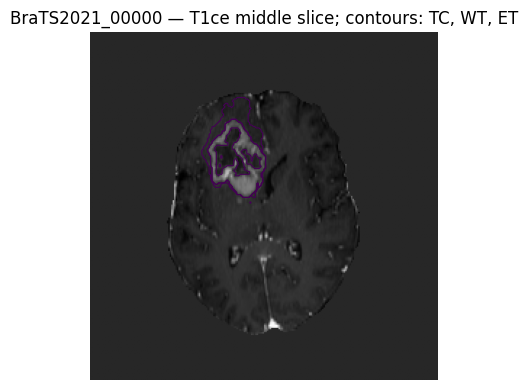

Segmentation QC figure: /content/drive/MyDrive/BrainMRI_Data/runs/Unified_End_to_End/segmentation_qc.png


In [11]:
import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np

qc_path = OUT / "segmentation_qc.png"
n = len(scan_specs)
fig, axes = plt.subplots(n, 1, figsize=(8, max(4, 4*n)), squeeze=False)
for ax, (case_id, folder) in zip(axes[:, 0], scan_specs):
    image_path = Path(folder) / "t1ce.nii.gz"
    img = nib.load(str(image_path))
    image_arr = np.asarray(img.dataobj)
    pred_img = nib.load(str(PRED_DIR / f"{case_id}.nii.gz"))
    pred_arr = np.asarray(pred_img.dataobj)
    if image_arr.shape[:3] != pred_arr.shape[:3]:
        ax.text(0.5, 0.5, f"Shape mismatch: {case_id}", ha="center", va="center")
        ax.set_axis_off()
        continue
    z = image_arr.shape[2] // 2
    base_slice = np.rot90(image_arr[:, :, z])
    seg_slice = np.rot90(pred_arr[:, :, z])
    ax.imshow(base_slice, cmap="gray")
    # Distinct contour levels are labelled in the legend/title; contours are for visual QC only.
    for region, labels in REGIONS.items():
        region_slice = np.isin(seg_slice, labels)
        if region_slice.any():
            ax.contour(region_slice.astype(float), levels=[0.5], linewidths=0.8)
    ax.set_title(f"{case_id} — T1ce middle slice; contours: TC, WT, ET")
    ax.axis("off")
fig.tight_layout()
fig.savefig(qc_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Segmentation QC figure:", qc_path)


## 7. Uncertainty maps: official BraTS workflow and RHUH perturbation-stability workflow
BraTS uses the project's official M3-T04 workflow. RHUH uses repeated inference on modest intensity-perturbed copies of each modality; voxelwise disagreement is an approximate perturbation-sensitivity uncertainty map, not calibrated Bayesian uncertainty.


In [12]:
# Official M3-T04 uncertainty workflow with explicit CPU-safe nnU-Net TTA and fail-safe reporting.
from pathlib import Path
import json, subprocess, sys, time, os, shutil, importlib.util, re
from datetime import datetime, timezone

RUN_OFFICIAL_UNCERTAINTY = globals().get("RUN_OFFICIAL_UNCERTAINTY", True)
TASK_MODE = globals().get("TASK_MODE", "BRATS_SINGLE")
UNCERTAINTY_SAVE_MAPS = globals().get("UNCERTAINTY_SAVE_MAPS", 1)
MAX_HOURS_UNCERTAINTY = globals().get("MAX_HOURS_UNCERTAINTY", 2.0)
UNCERTAINTY_CASES = globals().get("UNCERTAINTY_CASES", 3)
_missing_setup = [name for name in ("BASE", "REPO", "MODEL_DIR") if name not in globals()]
if _missing_setup:
    raise RuntimeError("Uncertainty step needs setup variables: " + ", ".join(_missing_setup) + ". Run all cells from the beginning.")

uncertainty_summary = None
fresh_uncertainty_maps = []
uncertainty_status_path = None
uncertainty_summary_path = None
uncertainty_root = BASE / "runs/M3-T04_uncertainty"
uncertainty_root.mkdir(parents=True, exist_ok=True)
uncertainty_out = uncertainty_root / ("run_" + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ"))
uncertainty_out.mkdir(parents=True, exist_ok=False)
summary_file = uncertainty_out / "summary.json"
uncertainty_status = {
    "workflow": "M3-T04 official BraTS cohort uncertainty",
    "status": "not_run", "official_summary_exists": False, "map_count": 0,
    "map_files": [], "script_exit_code": None, "error": None,
    "note": "Completion requires successful official script exit, readable summary.json, and at least one map file."
}
print("Fresh official uncertainty output folder:", uncertainty_out)

if RUN_OFFICIAL_UNCERTAINTY and TASK_MODE == "BRATS_SINGLE":
    try:
        processed = Path("/content/processed/brats2021")
        local_cases_exist = processed.is_dir() and any(processed.glob("BraTS2021_*"))
        if not local_cases_exist:
            CLEANED_TAR = BASE / "processed/brats2021_trainval_v1.tar"
            archive_candidates = [CLEANED_TAR] if CLEANED_TAR.is_file() else []
            for search_root in (BASE / "processed", Path("/content/drive/.shortcut-targets-by-id")):
                if search_root.is_dir():
                    try: archive_candidates.extend(search_root.glob("**/brats2021_trainval_v1.tar"))
                    except (OSError, PermissionError): pass
            archive_candidates = list(dict.fromkeys(Path(p) for p in archive_candidates if Path(p).is_file()))
            if archive_candidates:
                archive = archive_candidates[0]
                print("Restoring cleaned BraTS cohort from archive:", archive)
                Path("/content/processed").mkdir(parents=True, exist_ok=True)
                subprocess.run(["tar", "-tf", str(archive)], check=True, stdout=subprocess.DEVNULL)
                subprocess.run(["tar", "-xf", str(archive), "-C", "/content/processed"], check=True)
                local_cases_exist = processed.is_dir() and any(processed.glob("BraTS2021_*"))
            if not local_cases_exist:
                standardize_path = BASE / "pipeline" / "standardize.py"
                if standardize_path.is_file():
                    print("Cleaned cohort unavailable; trying project standardize.py.")
                    sys.path.insert(0, str(standardize_path.parent))
                    import importlib
                    S = importlib.reload(sys.modules["standardize"]) if "standardize" in sys.modules else importlib.import_module("standardize")
                    jobs = S.regenerate(splits=("train", "val"), datasets=("brats2021",))
                    if hasattr(jobs, "status") and (jobs.status == "failed").any():
                        raise RuntimeError("standardize.py reported failed jobs:\n" + jobs[jobs.status == "failed"].head(10).to_string(index=False))
                    local_cases_exist = processed.is_dir() and any(processed.glob("BraTS2021_*"))
            if not local_cases_exist:
                raise FileNotFoundError("Cleaned BraTS cohort is unavailable under /content/processed/brats2021.")
        else:
            print("Using already-extracted cleaned BraTS cohort.")

        # Patch the project TTA helper at SOURCE level. A fresh subprocess imports this source,
        # so the device override is applied inside scripts/uncertainty.py, not only in this notebook kernel.
        tta_file = REPO / "src/bmts/uncertainty/nnunet_tta.py"
        if not tta_file.is_file():
            raise FileNotFoundError(f"TTA helper not found: {tta_file}")
        tta_source = tta_file.read_text(encoding="utf-8")
        signature = re.search(r"(?m)^(\s*)def\s+predict_case_tta\s*\(([^)]*)\)\s*:", tta_source)
        if not signature:
            raise RuntimeError("Could not locate predict_case_tta() safely; uncertainty was not started.")
        cpu_marker = "# UNIFIED_NOTEBOOK_CPU_TTA_OVERRIDE"
        if cpu_marker not in tta_source:
            indent = signature.group(1) + "    "
            patch = ("\n" + indent + cpu_marker + "\n"
                     + indent + "import torch\n"
                     + indent + "_tta_device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')\n"
                     + indent + "predictor.device = _tta_device\n"
                     + indent + "predictor.perform_everything_on_device = (_tta_device.type == 'cuda')\n"
                     + indent + "if getattr(predictor, 'network', None) is not None:\n"
                     + indent + "    predictor.network.to(_tta_device)\n")
            patched = tta_source[:signature.end()] + patch + tta_source[signature.end():]
            compile(patched, str(tta_file), "exec")
            tta_file.write_text(patched, encoding="utf-8")
            print("Applied verified CPU override to:", tta_file)
        else:
            print("CPU override already present in:", tta_file)
        # Remove stale bytecode so the subprocess compiles the patched source.
        cache_dir = tta_file.parent / "__pycache__"
        if cache_dir.exists():
            for pyc in cache_dir.glob("nnunet_tta.*.pyc"):
                try: pyc.unlink()
                except OSError: pass

        cmd = [sys.executable, str(REPO / "scripts/uncertainty.py"), "--model-dir", str(MODEL_DIR),
               "--out", str(uncertainty_out), "--save-maps", str(UNCERTAINTY_SAVE_MAPS),
               "--max-hours", str(MAX_HOURS_UNCERTAINTY)]
        if UNCERTAINTY_CASES is not None:
            cmd.extend(["--cases", str(int(UNCERTAINTY_CASES))])
        env = os.environ.copy()
        env["PYTHONDONTWRITEBYTECODE"] = "1"
        print("Running official uncertainty workflow on CPU-safe TTA:", " ".join(cmd))
        result = subprocess.run(cmd, cwd=str(REPO), text=True, capture_output=True, check=False, env=env)
        if result.stdout:
            print("\n===== Official uncertainty STDOUT =====\n", result.stdout)
        if result.stderr:
            print("\n===== Official uncertainty STDERR =====\n", result.stderr)
        uncertainty_status["script_exit_code"] = int(result.returncode)
        if result.returncode != 0:
            uncertainty_status["error"] = (result.stderr or result.stdout or "Official uncertainty script returned non-zero exit.")[-6000:]

        map_candidates = []
        if UNCERTAINTY_SAVE_MAPS:
            for pattern in ("*.nii.gz", "*.nii", "*.png", "*.npy", "*.npz"):
                map_candidates.extend(uncertainty_out.rglob(pattern))
        fresh_uncertainty_maps = sorted({p.resolve() for p in map_candidates if p.is_file()})
        if summary_file.is_file():
            try:
                uncertainty_summary = json.loads(summary_file.read_text(encoding="utf-8"))
                uncertainty_summary_path = summary_file
                uncertainty_status["official_summary_exists"] = True
                if result.returncode == 0 and fresh_uncertainty_maps:
                    uncertainty_status["status"] = "complete"
                elif result.returncode != 0:
                    uncertainty_status["status"] = "script_failed_partial_outputs"
                else:
                    uncertainty_status["status"] = "summary_exists_but_maps_missing"
            except (json.JSONDecodeError, OSError) as e:
                uncertainty_status["status"] = "summary_unreadable"
                uncertainty_status["error"] = f"{type(e).__name__}: {e}"
        elif fresh_uncertainty_maps and result.returncode == 0:
            uncertainty_status["status"] = "maps_saved_summary_missing"
        else:
            uncertainty_status["status"] = "no_maps_found" if not fresh_uncertainty_maps else "script_failed_partial_outputs"
    except Exception as e:
        # Keep the rest of the notebook runnable and preserve a machine-readable failure report.
        uncertainty_status["status"] = "failed"
        uncertainty_status["error"] = f"{type(e).__name__}: {e}"
        print("Uncertainty workflow failed; core segmentation outputs are preserved.")
        print(uncertainty_status["error"])

    uncertainty_status["map_count"] = len(fresh_uncertainty_maps)
    uncertainty_status["map_files"] = [str(p) for p in fresh_uncertainty_maps]
    uncertainty_status["official_summary_exists"] = bool(summary_file.is_file())
    uncertainty_status_path = uncertainty_out / "pipeline_status.json"
    uncertainty_status_path.write_text(json.dumps(uncertainty_status, indent=2), encoding="utf-8")
    print("Uncertainty status:", uncertainty_status["status"])
    print("Uncertainty status file:", uncertainty_status_path)
    if uncertainty_summary_path:
        print("Official uncertainty summary:", uncertainty_summary_path)
    if not fresh_uncertainty_maps:
        print("WARNING: uncertainty maps are still missing; inspect the recorded error/status before reporting the run as complete.")
elif RUN_OFFICIAL_UNCERTAINTY and TASK_MODE == "RHUH_LONGITUDINAL":
    uncertainty_status["status"] = "skipped_unsupported_mode"
    uncertainty_status["note"] = "Official M3-T04 workflow is BraTS-cohort-specific; it does not calculate RHUH longitudinal uncertainty."
    uncertainty_status_path = uncertainty_out / "pipeline_status.json"
    uncertainty_status_path.write_text(json.dumps(uncertainty_status, indent=2), encoding="utf-8")
    print("Skipped official uncertainty: this workflow supports BraTS cohort cases, not RHUH follow-up scans.")
else:
    uncertainty_status["status"] = "disabled_by_configuration"
    uncertainty_status_path = uncertainty_out / "pipeline_status.json"
    uncertainty_status_path.write_text(json.dumps(uncertainty_status, indent=2), encoding="utf-8")
    print("Official uncertainty step skipped (RUN_OFFICIAL_UNCERTAINTY=False).")


Fresh official uncertainty output folder: /content/drive/MyDrive/BrainMRI_Data/runs/M3-T04_uncertainty/run_20261026T183350540150Z
Using already-extracted cleaned BraTS cohort.
Applied verified CPU override to: /content/repo/src/bmts/uncertainty/nnunet_tta.py
Running official uncertainty workflow on CPU-safe TTA: /usr/bin/python3 /content/repo/scripts/uncertainty.py --model-dir /content/drive/MyDrive/BrainMRI_Data/runs/M2-T04_nnunet/nnUNet_results/Dataset501_BraTS2021/nnUNetTrainer_50epochs__nnUNetPlans__3d_fullres --out /content/drive/MyDrive/BrainMRI_Data/runs/M3-T04_uncertainty/run_20261026T183350540150Z --save-maps 1 --max-hours 2.0 --cases 3

===== Official uncertainty STDOUT =====
 3 validation patients, 0 already done
[1/3] BraTS2021_00032: Dice WT 0.956 TC 0.964 ET 0.928 | uncertainty 0.081 | 71.8 s
[2/3] BraTS2021_00059: Dice WT 0.951 TC 0.966 ET 0.946 | uncertainty 0.088 | 75.0 s
[3/3] BraTS2021_00077: Dice WT 0.943 TC 0.981 ET 0.961 | uncertainty 0.105 | 73.5 s
UNCERTAINTY FI

In [20]:
# RHUH-specific perturbation-stability uncertainty.
# This estimates sensitivity to small intensity perturbations; it is NOT calibrated probability uncertainty.
if TASK_MODE == "RHUH_LONGITUDINAL":
    import numpy as np, nibabel as nib, shutil, subprocess, os, json
    from pathlib import Path
    import pandas as pd
    rhuh_uncertainty_dir = OUT / "uncertainty_rhuh_perturbation"
    rhuh_uncertainty_dir.mkdir(parents=True, exist_ok=True)
    nnunet_executable = shutil.which("nnUNetv2_predict")
    if nnunet_executable is None:
        raise RuntimeError("RHUH uncertainty needs nnUNetv2_predict. Run setup and inference cells first.")
    # Input files are the already standardized four-channel nnU-Net inputs created in cell 4.
    # The original predictions are retained; perturbation predictions are written to isolated folders.
    perturbation_runs = int(globals().get("RHUH_UNCERTAINTY_RUNS", 4))
    perturbation_sigma = float(globals().get("RHUH_UNCERTAINTY_SIGMA", 0.03))
    if perturbation_runs < 2:
        raise ValueError("RHUH_UNCERTAINTY_RUNS must be >= 2 to estimate disagreement.")
    if not (0.0 < perturbation_sigma <= 0.15):
        raise ValueError("RHUH_UNCERTAINTY_SIGMA must be in (0, 0.15].")
    # Reuse the inference device selected in the inference cell; CPU is supported but slower.
    device_args = globals().get("_device_args", ["-device", "cpu"])
    uncertainty_rows = []
    for case_id, folder in scan_specs:
        input_files = [IN_DIR / f"{case_id}_{i:04d}.nii.gz" for i in range(4)]
        missing_inputs = [str(x) for x in input_files if not x.is_file()]
        if missing_inputs:
            raise FileNotFoundError("Cannot create RHUH uncertainty; missing standardized inputs: " + ", ".join(missing_inputs))
        ref_img = nib.load(str(PRED_DIR / f"{case_id}.nii.gz"))
        pred_arrays = [np.asarray(ref_img.dataobj).astype(np.int16)]
        rng = np.random.default_rng(20261024)
        for run_idx in range(perturbation_runs):
            run_root = rhuh_uncertainty_dir / f"{case_id}_run_{run_idx+1:02d}"
            run_in, run_out = run_root / "input", run_root / "prediction"
            run_in.mkdir(parents=True, exist_ok=True)
            run_out.mkdir(parents=True, exist_ok=True)
            for src in input_files:
                img = nib.load(str(src))
                arr = np.asarray(img.dataobj, dtype=np.float32)
                finite = np.isfinite(arr)
                vals = arr[finite]
                if vals.size == 0:
                    raise ValueError(f"Input modality contains no finite values: {src}")
                # Apply small multiplicative noise to non-background voxels; preserve geometry and shape.
                scale = max(float(np.percentile(np.abs(vals), 99)), 1e-6)
                noise = rng.normal(0.0, perturbation_sigma * scale, size=arr.shape).astype(np.float32)
                perturbed = arr.copy()
                nonzero = np.abs(arr) > (1e-6 * scale)
                perturbed[nonzero] = arr[nonzero] + noise[nonzero]
                perturbed[~finite] = 0
                out_img = nib.Nifti1Image(perturbed, img.affine, img.header.copy())
                nib.save(out_img, str(run_in / src.name))
            cmd_unc = [nnunet_executable, "-i", str(run_in), "-o", str(run_out), "-d", "501", "-c", "3d_fullres", "-f", "0", "-tr", "nnUNetTrainer_50epochs", "-chk", "checkpoint_best.pth", *device_args]
            proc = subprocess.run(cmd_unc, text=True, capture_output=True, check=False)
            if proc.returncode != 0:
                raise RuntimeError(f"RHUH uncertainty inference failed for {case_id}, run {run_idx+1}. STDERR:\n{proc.stderr[-5000:]}")
            pred_path = run_out / f"{case_id}.nii.gz"
            if not pred_path.is_file():
                raise FileNotFoundError(f"Uncertainty run did not create expected prediction: {pred_path}")
            run_img = nib.load(str(pred_path))
            run_arr = np.asarray(run_img.dataobj).astype(np.int16)
            if run_arr.shape != pred_arrays[0].shape or not np.allclose(run_img.affine, ref_img.affine, atol=1e-4):
                raise ValueError(f"Uncertainty prediction geometry mismatch for {case_id} run {run_idx+1}")
            pred_arrays.append(run_arr)
        stack = np.stack(pred_arrays, axis=0)
        # Per-voxel label disagreement: 1 - fraction of runs agreeing with the modal label.
        uncertainty = np.zeros(stack.shape[1:], dtype=np.float32)
        for label in np.unique(stack):
            uncertainty = np.maximum(uncertainty, (stack == label).mean(axis=0).astype(np.float32))
        uncertainty = 1.0 - uncertainty
        unc_img = nib.Nifti1Image(uncertainty, ref_img.affine, ref_img.header.copy())
        unc_img.set_data_dtype(np.float32)
        unc_path = rhuh_uncertainty_dir / f"{case_id}_uncertainty_disagreement.nii.gz"
        nib.save(unc_img, str(unc_path))
        # Also save a compact report with range and summary statistics.
        uncertainty_rows.append({"case_id": case_id, "method": "intensity_perturbation_label_disagreement", "perturbation_runs": perturbation_runs, "sigma_fraction_p99": perturbation_sigma, "uncertainty_map": str(unc_path), "mean_uncertainty": float(uncertainty.mean()), "max_uncertainty": float(uncertainty.max()), "note": "Approximate perturbation sensitivity; not calibrated Bayesian uncertainty."})
    rhuh_uncertainty_csv = rhuh_uncertainty_dir / "rHuh_uncertainty_summary.csv"
    pd.DataFrame(uncertainty_rows).to_csv(rhuh_uncertainty_csv, index=False)
    uncertainty_status_path = rhuh_uncertainty_dir / "pipeline_status.json"
    uncertainty_status_path.write_text(json.dumps({"task_mode": TASK_MODE, "status": "completed", "method": "intensity_perturbation_label_disagreement", "calibrated": False, "cases": uncertainty_rows}, indent=2))
    fresh_uncertainty_maps = [Path(row["uncertainty_map"]) for row in uncertainty_rows]
    print("RHUH perturbation-stability uncertainty maps saved:", [str(p) for p in fresh_uncertainty_maps])


In [21]:
# Generate an uncertainty/disagreement map for the exact BraTS scan processed above.
# This is perturbation sensitivity, NOT calibrated Bayesian/probabilistic uncertainty.
if TASK_MODE == "BRATS_SINGLE":
    import numpy as np, nibabel as nib, pandas as pd, shutil, subprocess, json
    from pathlib import Path

    selected_uncertainty_dir = OUT / "uncertainty_selected_case"
    selected_uncertainty_dir.mkdir(parents=True, exist_ok=True)
    selected_uncertainty_rows = []
    selected_case_uncertainty_map = None
    selected_uncertainty_csv = selected_uncertainty_dir / "selected_case_uncertainty_summary.csv"
    _nnunet_executable = shutil.which("nnUNetv2_predict")
    if _nnunet_executable is None:
        raise RuntimeError("Selected-case uncertainty needs nnUNetv2_predict; run setup and inference cells first.")

    _selected_runs = int(globals().get("BRATS_UNCERTAINTY_PERTURBATION_RUNS", 3))
    _selected_sigma = float(globals().get("BRATS_UNCERTAINTY_SIGMA", 0.03))
    if _selected_runs < 2:
        raise ValueError("BRATS_UNCERTAINTY_PERTURBATION_RUNS must be >= 2.")
    if not (0.0 < _selected_sigma <= 0.15):
        raise ValueError("BRATS_UNCERTAINTY_SIGMA must be in (0, 0.15].")

    _device_args_selected = globals().get("_device_args", ["-device", "cpu"])
    for _case_id, _folder in scan_specs:
        _base_pred_path = PRED_DIR / f"{_case_id}.nii.gz"
        if not _base_pred_path.is_file():
            raise FileNotFoundError(f"Cannot create selected-case uncertainty; missing base mask: {_base_pred_path}")
        _base_img = nib.load(str(_base_pred_path))
        _base_seg = np.asarray(_base_img.dataobj).astype(np.int16)
        _prediction_arrays = [_base_seg]
        _rng = np.random.default_rng(20261026)
        _input_files = [IN_DIR / f"{_case_id}_{_i:04d}.nii.gz" for _i in range(4)]
        _missing_inputs = [str(_p) for _p in _input_files if not _p.is_file()]
        if _missing_inputs:
            raise FileNotFoundError("Cannot create selected-case uncertainty; missing nnU-Net inputs: " + ", ".join(_missing_inputs))

        for _run_idx in range(_selected_runs):
            _run_root = selected_uncertainty_dir / f"{_case_id}_run_{_run_idx+1:02d}"
            # Remove old run outputs so a rerun cannot accidentally reuse stale predictions.
            if _run_root.exists():
                shutil.rmtree(_run_root)
            _run_in, _run_out = _run_root / "input", _run_root / "prediction"
            _run_in.mkdir(parents=True, exist_ok=True)
            _run_out.mkdir(parents=True, exist_ok=True)
            for _src in _input_files:
                _img = nib.load(str(_src))
                _arr = np.asarray(_img.dataobj, dtype=np.float32)
                _finite = np.isfinite(_arr)
                _vals = _arr[_finite]
                if _vals.size == 0:
                    raise ValueError(f"Input modality contains no finite values: {_src}")
                _scale = max(float(np.percentile(np.abs(_vals), 99)), 1e-6)
                _noise = _rng.normal(0.0, _selected_sigma * _scale, size=_arr.shape).astype(np.float32)
                _perturbed = _arr.copy()
                # Preserve background voxels; perturb only non-background finite voxels.
                _nonzero = _finite & (np.abs(_arr) > (1e-6 * _scale))
                _perturbed[_nonzero] = _arr[_nonzero] + _noise[_nonzero]
                _perturbed[~_finite] = 0
                _out_img = nib.Nifti1Image(_perturbed, _img.affine, _img.header.copy())
                _out_img.set_data_dtype(np.float32)
                nib.save(_out_img, str(_run_in / _src.name))

            _cmd = [
                _nnunet_executable, "-i", str(_run_in), "-o", str(_run_out),
                "-d", "501", "-c", "3d_fullres", "-f", "0",
                "-tr", "nnUNetTrainer_50epochs", "-chk", "checkpoint_best.pth",
                *_device_args_selected,
            ]
            _proc = subprocess.run(_cmd, text=True, capture_output=True, check=False)
            if _proc.returncode != 0:
                raise RuntimeError(
                    f"Selected-case uncertainty inference failed for {_case_id}, perturbation {_run_idx+1}.\n"
                    f"STDERR:\n{_proc.stderr[-5000:]}\nSTDOUT:\n{_proc.stdout[-2000:]}"
                )
            _pred_path = _run_out / f"{_case_id}.nii.gz"
            if not _pred_path.is_file():
                raise FileNotFoundError(f"Perturbed inference did not create expected prediction: {_pred_path}")
            _run_img = nib.load(str(_pred_path))
            _run_arr = np.asarray(_run_img.dataobj).astype(np.int16)
            if _run_arr.shape != _base_seg.shape or not np.allclose(_run_img.affine, _base_img.affine, atol=1e-4):
                raise ValueError(f"Uncertainty prediction geometry mismatch for {_case_id}, run {_run_idx+1}")
            _prediction_arrays.append(_run_arr)

        # Per-voxel uncertainty = 1 - the fraction of predictions agreeing on the most common label.
        _stack = np.stack(_prediction_arrays, axis=0)
        _agreement = np.zeros(_stack.shape[1:], dtype=np.float32)
        for _label in np.unique(_stack):
            _agreement = np.maximum(_agreement, (_stack == _label).mean(axis=0).astype(np.float32))
        _uncertainty = 1.0 - _agreement
        _unc_img = nib.Nifti1Image(_uncertainty.astype(np.float32), _base_img.affine, _base_img.header.copy())
        _unc_img.set_data_dtype(np.float32)
        selected_case_uncertainty_map = selected_uncertainty_dir / f"{_case_id}_uncertainty_disagreement.nii.gz"
        nib.save(_unc_img, str(selected_case_uncertainty_map))
        selected_uncertainty_rows.append({
            "case_id": _case_id,
            "method": "original_plus_intensity_perturbation_label_disagreement",
            "perturbation_runs": _selected_runs,
            "sigma_fraction_p99": _selected_sigma,
            "uncertainty_map": str(selected_case_uncertainty_map),
            "mean_uncertainty": float(_uncertainty.mean()),
            "max_uncertainty": float(_uncertainty.max()),
            "note": "Approximate perturbation sensitivity; not calibrated probability uncertainty."
        })

    pd.DataFrame(selected_uncertainty_rows).to_csv(selected_uncertainty_csv, index=False)
    selected_uncertainty_status = {
        "task_mode": TASK_MODE,
        "status": "completed",
        "method": "original_plus_intensity_perturbation_label_disagreement",
        "calibrated": False,
        "maps": selected_uncertainty_rows
    }
    (selected_uncertainty_dir / "pipeline_status.json").write_text(
        json.dumps(selected_uncertainty_status, indent=2), encoding="utf-8"
    )
    print("Selected BraTS scan uncertainty map:", selected_case_uncertainty_map)
    print("Selected-case uncertainty summary:", selected_uncertainty_csv)
else:
    selected_case_uncertainty_map = None
    selected_uncertainty_csv = None


Selected BraTS scan uncertainty map: /content/drive/MyDrive/BrainMRI_Data/runs/Unified_End_to_End/uncertainty_selected_case/BraTS2021_00000_uncertainty_disagreement.nii.gz
Selected-case uncertainty summary: /content/drive/MyDrive/BrainMRI_Data/runs/Unified_End_to_End/uncertainty_selected_case/selected_case_uncertainty_summary.csv


## 8. Save a run summary and check expected outputs

In [14]:
# Final output verification. Uncertainty is reported by status and is not falsely marked complete if its official summary/maps are absent.
from pathlib import Path
import json, subprocess

_missing_final_setup = [name for name in ("BASE", "TASK_MODE", "OUT", "volumes_path", "PRED_DIR", "scan_specs", "SAVE_RAD_FEATURES", "changes_path", "RUN_OFFICIAL_UNCERTAINTY") if name not in globals()]
if _missing_final_setup:
    raise RuntimeError(
        "Final verification cannot run because these pipeline variables are missing: "
        + ", ".join(_missing_final_setup)
        + ". Run the notebook from the first cell in order (Runtime > Run all), then rerun final verification."
    )

uncertainty_out = globals().get("uncertainty_out", BASE / "runs/M3-T04_uncertainty")
status_candidate = uncertainty_out / "pipeline_status.json"
summary_candidate = uncertainty_out / "summary.json"
uncertainty_status_path = status_candidate if status_candidate.is_file() else None
uncertainty_summary_path = summary_candidate if RUN_OFFICIAL_UNCERTAINTY and TASK_MODE == "BRATS_SINGLE" and summary_candidate.is_file() else None
fresh_uncertainty_maps = globals().get("fresh_uncertainty_maps", [])

summary = {
    "pipeline": "Unified Brain MRI project-compatible pipeline",
    "task_mode": TASK_MODE,
    "repository": str(REPO),
    "repository_commit": subprocess.check_output(["git", "-C", str(REPO), "rev-parse", "HEAD"], text=True).strip(),
    "registered_model": "seg-model v1 / Dataset501_BraTS2021 / nnUNetTrainer_50epochs__nnUNetPlans__3d_fullres / fold_0",
    "checkpoint": str(checkpoint),
    "checkpoint_sha256_verified": True,
    "cases": [
        {
            "case_id": case_id,
            "folder": str(folder),
            "prediction": str(PRED_DIR / f"{case_id}.nii.gz"),
            "expert_mask": str(Path(folder) / "seg.nii.gz") if TASK_MODE == "RHUH_LONGITUDINAL" else None,
        }
        for case_id, folder in scan_specs
    ],
    "outputs": {
        "volumes_csv": str(volumes_path),
        "longitudinal_changes_csv": str(changes_path) if changes_path else None,
        "radiomics_csv": str(radiomics_path) if SAVE_RAD_FEATURES else None,
        "segmentation_metrics_csv": str(metrics_path) if "metrics_path" in globals() and metrics_path.is_file() else None,
        "segmentation_qc_figure": str(qc_path) if "qc_path" in globals() and qc_path.is_file() else None,
        "predictions_dir": str(PRED_DIR),
        "official_uncertainty_dir": str(uncertainty_out) if RUN_OFFICIAL_UNCERTAINTY and TASK_MODE == "BRATS_SINGLE" else None,
        "official_uncertainty_summary": str(uncertainty_summary_path) if uncertainty_summary_path else None,
        "uncertainty_status": str(uncertainty_status_path) if uncertainty_status_path else None,
        "uncertainty_maps": [str(p) for p in fresh_uncertainty_maps],
    },
    "notes": [
        "Predicted masks are not expert ground truth.",
        "Longitudinal changes require at least two timepoints for the same subject.",
        f"Percentage change is suppressed when the baseline region volume is below {MIN_VOL_CM3_FOR_PERCENT_CHANGE} cm3.",
        "The official M3-T04 uncertainty workflow evaluates a BraTS cohort and does not guarantee a map specifically for the selected single scan.",
        "Official uncertainty is complete only when the script creates a readable summary.json; inspect pipeline_status.json for partial or failed runs.",
        "RHUH post-operative/recurrence scans may be outside the model training distribution.",
        "Unknown NIfTI spatial units are assumed to be mm for volume conversion; check headers before scientific reporting.",
        "Official uncertainty failure is reported explicitly and does not invalidate already-generated core outputs.",
        "Review PyRadiomics configuration and warnings before interpreting extracted features scientifically.",
    ],
}
summary_path = OUT / "run_summary.json"
summary_path.write_text(json.dumps(summary, indent=2))

# These are the mandatory core outputs. Optional official uncertainty artifacts are checked separately below.
expected = [volumes_path, summary_path] + [PRED_DIR / f"{case_id}.nii.gz" for case_id, _ in scan_specs]
if SAVE_RAD_FEATURES:
    expected.append(radiomics_path)
if "metrics_path" in globals():
    expected.append(metrics_path)
if "qc_path" in globals():
    expected.append(qc_path)
if changes_path:
    expected.append(changes_path)
missing = [str(path) for path in expected if not path.is_file()]
if missing:
    raise RuntimeError("Core output verification failed; missing files:\n" + "\n".join(missing))

print("\nCORE PIPELINE OUTPUTS VERIFIED")
for path in expected:
    print(" -", path)
if RUN_OFFICIAL_UNCERTAINTY and TASK_MODE == "BRATS_SINGLE":
    status = {}
    if uncertainty_status_path and uncertainty_status_path.is_file():
        try:
            status = json.loads(uncertainty_status_path.read_text())
        except (OSError, json.JSONDecodeError):
            status = {"status": "status_file_unreadable"}
    print("Official uncertainty status:", status.get("status", "not_run"))
    print("Uncertainty maps found:", len(fresh_uncertainty_maps))
    if uncertainty_summary_path is None or not fresh_uncertainty_maps or status.get("status") != "complete":
        print("WARNING: official uncertainty is not confirmed complete. Check the uncertainty output directory and pipeline_status.json; rerun the uncertainty cell after resolving the reported issue.")
if TASK_MODE == "BRATS_SINGLE":
    print("Longitudinal changes: not applicable to one scan; use RHUH_LONGITUDINAL with at least two timepoints.")
print("Run summary:", summary_path)



CORE PIPELINE OUTPUTS VERIFIED
 - /content/drive/MyDrive/BrainMRI_Data/runs/Unified_End_to_End/tumor_volumes.csv
 - /content/drive/MyDrive/BrainMRI_Data/runs/Unified_End_to_End/run_summary.json
 - /content/drive/MyDrive/BrainMRI_Data/runs/Unified_End_to_End/predictions/BraTS2021_00000.nii.gz
 - /content/drive/MyDrive/BrainMRI_Data/runs/Unified_End_to_End/radiomics_features.csv
 - /content/drive/MyDrive/BrainMRI_Data/runs/Unified_End_to_End/segmentation_metrics.csv
 - /content/drive/MyDrive/BrainMRI_Data/runs/Unified_End_to_End/segmentation_qc.png
Official uncertainty status: complete
Uncertainty maps found: 10
Longitudinal changes: not applicable to one scan; use RHUH_LONGITUDINAL with at least two timepoints.
Run summary: /content/drive/MyDrive/BrainMRI_Data/runs/Unified_End_to_End/run_summary.json


## 9. Export a portable results bundle
Creates a ZIP containing the prediction masks, CSV/JSON reports, and official uncertainty summary/status plus saved maps from this run. It does not include raw MRI inputs or the full model checkpoint.

In [26]:
from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/BrainMRI_Data")

print("Project folder exists:", PROJECT_ROOT.exists())

if PROJECT_ROOT.exists():
    matches = list(PROJECT_ROOT.rglob("tumor_volumes.csv"))

    if matches:
        print("Found tumor_volumes.csv:")
        for path in matches:
            print(path)
    else:
        print("tumor_volumes.csv was NOT found inside BrainMRI_Data")

        output_dir = PROJECT_ROOT / "runs" / "Unified_End_to_End"
        print("\nExpected output folder exists:", output_dir.exists())

        if output_dir.exists():
            print("\nFiles in the output folder:")
            for path in output_dir.iterdir():
                print(path.name)

Project folder exists: True
tumor_volumes.csv was NOT found inside BrainMRI_Data

Expected output folder exists: True

Files in the output folder:
nnunet_input
predictions
BUNDLE_README.txt
verified_uncertainty_path.txt
run_summary.json
output_bundle.zip
segmentation_metrics.csv
tumor_volumes.csv
segmentation_qc.png
radiomics_features.csv
uncertainty_selected_case


In [27]:
from pathlib import Path
import zipfile
import json

# Output directory
OUTPUT_DIR = Path(
    "/content/drive/MyDrive/BrainMRI_Data/runs/Unified_End_to_End"
)

BUNDLE_PATH = OUTPUT_DIR / "output_bundle.zip"

# Required outputs
required_files = {
    "tumor_volumes.csv": OUTPUT_DIR / "tumor_volumes.csv",
    "radiomics_features.csv": OUTPUT_DIR / "radiomics_features.csv",
    "run_summary.json": OUTPUT_DIR / "run_summary.json",
    "segmentation_metrics.csv": OUTPUT_DIR / "segmentation_metrics.csv",
    "segmentation_qc.png": OUTPUT_DIR / "segmentation_qc.png",
}

# Find segmentation masks
mask_files = list((OUTPUT_DIR / "predictions").glob("*.nii.gz"))

# Find selected-case uncertainty maps
uncertainty_dir = OUTPUT_DIR / "uncertainty_selected_case"
uncertainty_maps = (
    list(uncertainty_dir.glob("*uncertainty*.nii.gz"))
    if uncertainty_dir.exists()
    else []
)

# Find selected-case uncertainty summaries
uncertainty_summaries = (
    list(uncertainty_dir.glob("*.csv"))
    if uncertainty_dir.exists()
    else []
)

# Validate required files
missing = [
    name for name, path in required_files.items()
    if not path.is_file()
]

if missing:
    raise FileNotFoundError(
        "Required output files are missing:\n"
        + "\n".join(missing)
    )

if not mask_files:
    raise FileNotFoundError(
        f"No segmentation masks found in {OUTPUT_DIR / 'predictions'}"
    )

if not uncertainty_maps:
    raise FileNotFoundError(
        f"No selected-case uncertainty map found in {uncertainty_dir}"
    )

# Collect files; use relative paths to avoid duplicate archive names
files_to_bundle = list(required_files.values())
files_to_bundle.extend(mask_files)
files_to_bundle.extend(uncertainty_maps)
files_to_bundle.extend(uncertainty_summaries)

readme = OUTPUT_DIR / "BUNDLE_README.txt"
if readme.is_file():
    files_to_bundle.append(readme)

# Remove duplicate source paths
files_to_bundle = list(dict.fromkeys(
    p.resolve() for p in files_to_bundle
))

# Create ZIP
with zipfile.ZipFile(
    BUNDLE_PATH, "w", compression=zipfile.ZIP_DEFLATED
) as zf:
    for path in files_to_bundle:
        # Preserve paths relative to the output directory
        try:
            archive_name = path.relative_to(OUTPUT_DIR.resolve())
        except ValueError:
            archive_name = Path(path.name)

        zf.write(path, arcname=str(archive_name))

# Verify ZIP
with zipfile.ZipFile(BUNDLE_PATH, "r") as zf:
    names = zf.namelist()
    name_set = set(names)
    duplicates = sorted({
        name for name in names if names.count(name) > 1
    })
    bad_file = zf.testzip()

    has_mask = any(
        name.startswith("predictions/") and name.endswith(".nii.gz")
        for name in names
    )

    has_volumes = "tumor_volumes.csv" in name_set
    has_radiomics = "radiomics_features.csv" in name_set

    has_uncertainty_map = any(
        name.startswith("uncertainty_selected_case/")
        and name.endswith(".nii.gz")
        and "uncertainty" in name.lower()
        for name in names
    )

    has_uncertainty_summary = any(
        name.startswith("uncertainty_selected_case/")
        and name.endswith(".csv")
        for name in names
    )

    print("=" * 45)
    print("OUTPUT BUNDLE VERIFICATION")
    print("=" * 45)
    print("ZIP:", BUNDLE_PATH)
    print("Files included:", len(names))
    print(f"Bundle size: {BUNDLE_PATH.stat().st_size / (1024**2):.2f} MB")
    print("Segmentation mask:", "PASS" if has_mask else "MISSING")
    print("Tumor volumes:", "PASS" if has_volumes else "MISSING")
    print("Radiomics features:", "PASS" if has_radiomics else "MISSING")
    print(
        "Selected-case uncertainty map:",
        "PASS" if has_uncertainty_map else "MISSING"
    )
    print(
        "Selected-case uncertainty summary:",
        "PASS" if has_uncertainty_summary else "MISSING"
    )
    print("Duplicate archive paths:", duplicates if duplicates else "NONE")
    print("ZIP integrity:", "PASS" if bad_file is None else f"FAILED: {bad_file}")

    if (
        not all([
            has_mask,
            has_volumes,
            has_radiomics,
            has_uncertainty_map,
            has_uncertainty_summary,
        ])
        or duplicates
        or bad_file is not None
    ):
        raise RuntimeError("Bundle verification failed.")

print("\nSUCCESS: All required output artifacts are included.")

OUTPUT BUNDLE VERIFICATION
ZIP: /content/drive/MyDrive/BrainMRI_Data/runs/Unified_End_to_End/output_bundle.zip
Files included: 9
Bundle size: 0.14 MB
Segmentation mask: PASS
Tumor volumes: PASS
Radiomics features: PASS
Selected-case uncertainty map: PASS
Selected-case uncertainty summary: PASS
Duplicate archive paths: NONE
ZIP integrity: PASS

SUCCESS: All required output artifacts are included.


In [28]:
from pathlib import Path
import zipfile

zip_path = Path(
    "/content/drive/MyDrive/BrainMRI_Data/runs/"
    "Unified_End_to_End/output_bundle.zip"
)

with zipfile.ZipFile(zip_path, "r") as zf:
    for name in zf.namelist():
        info = zf.getinfo(name)
        print(f"{name} — {info.file_size / 1024:.2f} KB")

tumor_volumes.csv — 0.22 KB
radiomics_features.csv — 73.97 KB
run_summary.json — 4.36 KB
segmentation_metrics.csv — 0.17 KB
segmentation_qc.png — 115.88 KB
predictions/BraTS2021_00000.nii.gz — 19.36 KB
uncertainty_selected_case/BraTS2021_00000_uncertainty_disagreement.nii.gz — 155.05 KB
uncertainty_selected_case/selected_case_uncertainty_summary.csv — 0.42 KB
BUNDLE_README.txt — 0.63 KB


## Final checklist before using results scientifically

- Run all cells from the beginning. The notebook uses CUDA when PyTorch supports it and safely falls back to CPU when CUDA is unavailable; CPU inference/uncertainty may be much slower.
- Confirm the Drive root, cleaned scans, and registered checkpoint are present. The cleaned BraTS tar archive is optional if /content/processed/brats2021 is already populated. The shared Drive folder must be added as a shortcut under My Drive or `BASE` must be changed to the actual location.
- `BRATS_SINGLE` processes one scan and does not generate longitudinal changes.
- `RHUH_LONGITUDINAL` requires at least two timepoints from the same patient and the folder names must match the configuration cell. Review predictions carefully, especially post-operative/recurrence scans.
- Dice/HD95 are meaningful only when a real expert/reference mask exists and is aligned with the prediction.
- Official M3-T04 uncertainty is a BraTS-cohort workflow; its summary/status is authoritative, and the selected input scan is not guaranteed to be among the mapped validation cases. It is skipped for RHUH.
- Percentage changes are suppressed for baseline volumes below the configured minimum to avoid unstable values.
- Review spatial units, radiomics settings, QC figures, and warnings before reporting measurements. This notebook is a research workflow, not a clinical diagnostic device.

- RHUH uncertainty is an approximate perturbation-sensitivity map, not calibrated Bayesian uncertainty.
- Confirm the RHUH reference-label mapping before interpreting reference-mask Dice/HD95 or expert-mask volumes; never assume the BraTS label semantics apply to RHUH.
- Longitudinal change is only biologically interpretable if the timepoints are registered to a common space and the label convention is consistent.
